In [3]:
import seaborn as sns
import plotly.express as px
import pandas as pd
import matplotlib.pyplot as plt

gap = px.data.gapminder()
gap_2007 = gap[gap["year"] == 2007]   # only the latest year

gap.head()


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


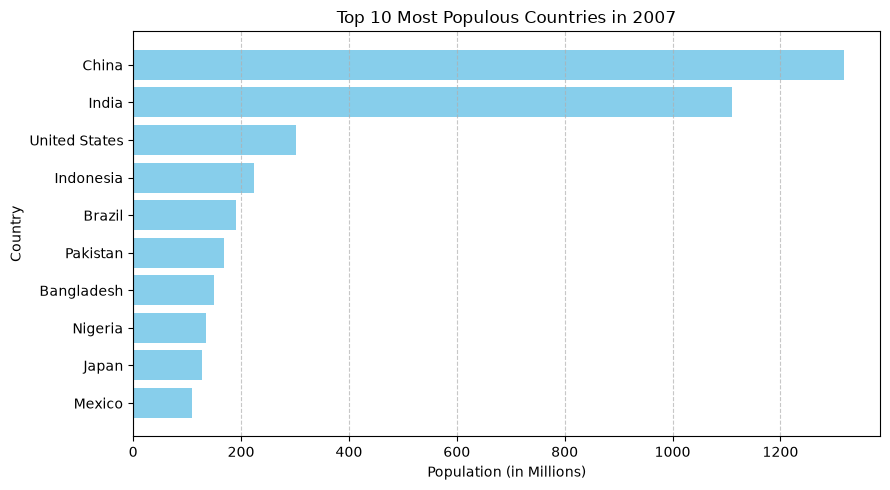

In [4]:
#Task 1: Ranked bar chart

top10_pop = gap_2007.nlargest(10, "pop").sort_values("pop", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(top10_pop["country"], top10_pop["pop"] / 1000000, color="skyblue")
plt.xlabel("Population (in Millions)")
plt.ylabel("Country")
plt.title("Top 10 Most Populous Countries in 2007")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Which two countries are far ahead of the rest?

China and India are far ahead of all other countries in population, both exceeding 1 billion people.

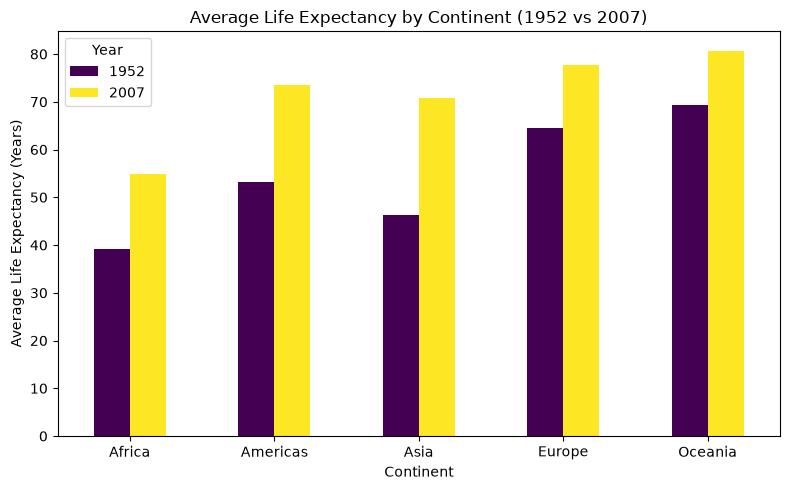

In [5]:
#Task 2 : Grouped bar chart

g = (
    gap[gap["year"].isin([1952, 2007])]
    .groupby(["continent", "year"])["lifeExp"]
    .mean()
    .unstack()
)

g.plot(kind="bar", figsize=(8, 5), colormap="viridis")
plt.title("Average Life Expectancy by Continent (1952 vs 2007)")
plt.xlabel("Continent")
plt.ylabel("Average Life Expectancy (Years)")
plt.xticks(rotation=0)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

#Which continent improved the most between 1952 and 2007?

Asia improved the most, showing the largest absolute increase in average life expectancy from 1952 to 2007.

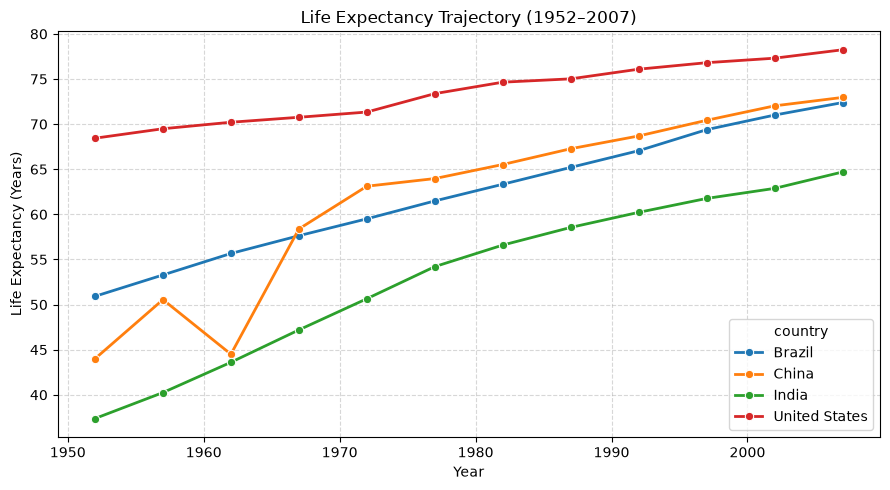

In [6]:
#Part B: Line Chart
#Task 3: Change over time

selected_countries = ["India", "China", "Brazil", "United States"]
filtered_gap = gap[gap["country"].isin(selected_countries)]

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=filtered_gap,
    x="year",
    y="lifeExp",
    hue="country",
    marker="o",
    linewidth=2,
)
plt.title("Life Expectancy Trajectory (1952–2007)")
plt.xlabel("Year")
plt.ylabel("Life Expectancy (Years)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#Which country started with the lowest life expectancy and which 

one improved the fastest?
China started with the lowest life expectancy in 1952 among these four countries, and China also improved the fastest overall.

#Why is a line chart the right choice here?

A line chart is ideal because time is continuous, and line plots effectively convey trends, trajectories, and rates of change over continuous time intervals.

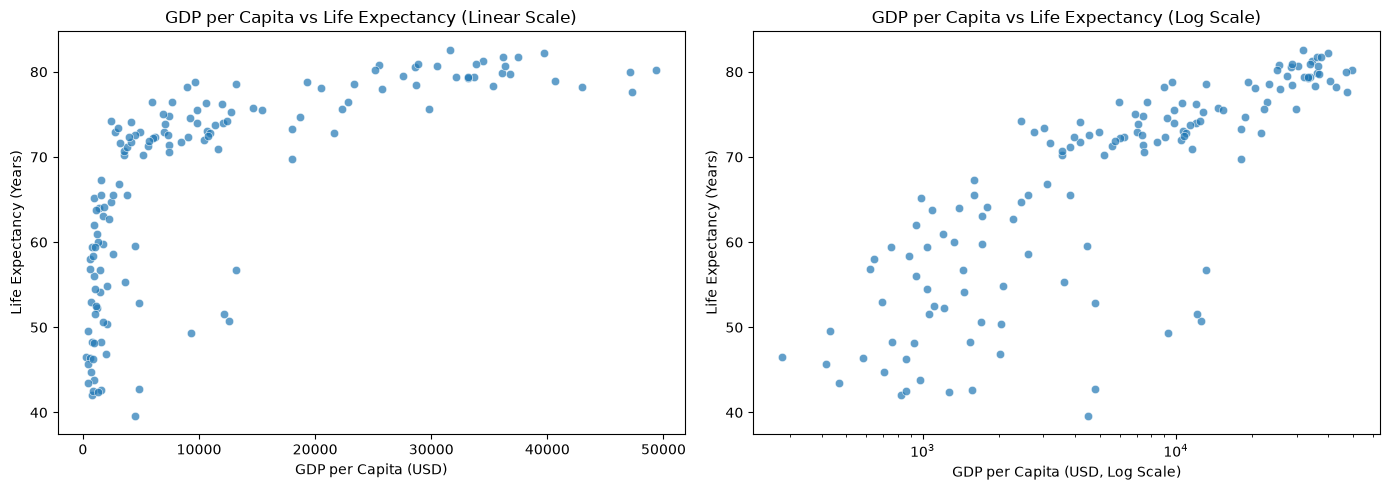

In [7]:
#Part C: Scatter Plots
#Task 4: Linear scale versus log scale

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Linear scale
sns.scatterplot(
    data=gap_2007, x="gdpPercap", y="lifeExp", ax=axes[0], alpha=0.7
)
axes[0].set_title("GDP per Capita vs Life Expectancy (Linear Scale)")
axes[0].set_xlabel("GDP per Capita (USD)")
axes[0].set_ylabel("Life Expectancy (Years)")

# Right plot: Log scale
sns.scatterplot(
    data=gap_2007, x="gdpPercap", y="lifeExp", ax=axes[1], alpha=0.7
)
axes[1].set_xscale("log")
axes[1].set_title("GDP per Capita vs Life Expectancy (Log Scale)")
axes[1].set_xlabel("GDP per Capita (USD, Log Scale)")
axes[1].set_ylabel("Life Expectancy (Years)")

plt.tight_layout()
plt.show()

#Which chart is easier to read, and why?

The plot with the Log Scale (Right Chart) is much easier to read. Income data is heavily skewed; the log scale spreads out lower-income countries (preventing clustering near the y-axis) and reveals a clear positive logarithmic relationship with life expectancy.

In [8]:
#Task 5: Bubble chart

fig = px.scatter(
    gap_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent",
    hover_name="country",
    log_x=True,
    size_max=50,
    title="Life Expectancy vs GDP per Capita (2007)",
)
fig.show()

#Which continent has most of the countries with low life expectancy?

Africa.

#Names of two of the largest bubbles:

China and India.

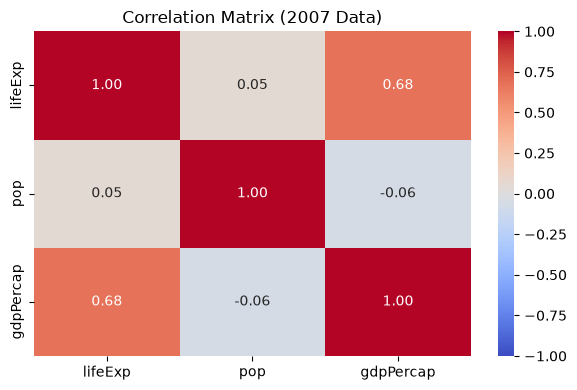

In [9]:
#Part D: Heatmaps
#Task 6: Correlation heatmap

corr_matrix = gap_2007[["lifeExp", "pop", "gdpPercap"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f"
)
plt.title("Correlation Matrix (2007 Data)")
plt.tight_layout()
plt.show()

#Which pair of columns is most strongly related?

lifeExp and gdpPercap have the strongest positive correlation.

#Which pair has almost no relationship?

pop and lifeExp (as well as pop and gdpPercap) show almost zero linear relationship.

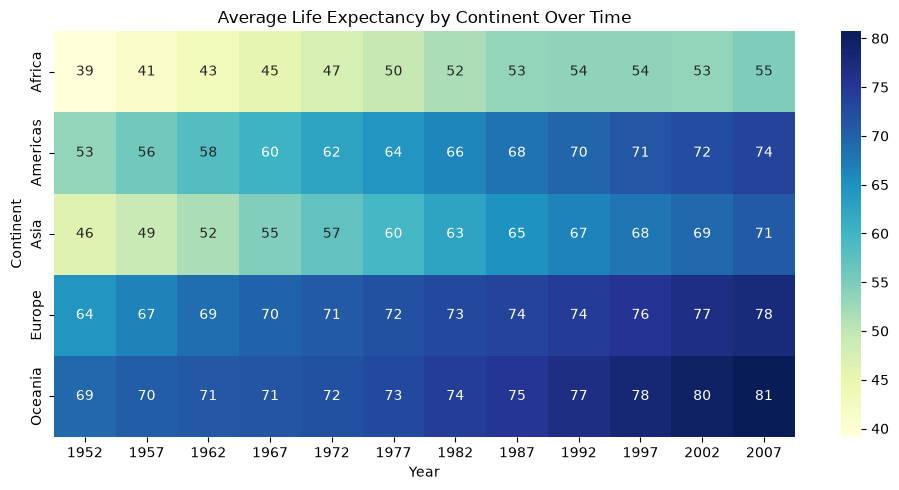

In [10]:
#Task 7: Pattern heatmap

pivot = gap.pivot_table(
    index="continent", columns="year", values="lifeExp", aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Life Expectancy by Continent Over Time")
plt.xlabel("Year")
plt.ylabel("Continent")
plt.tight_layout()
plt.show()

#Which continent has the lowest values throughout?

Africa consistently has the lowest life expectancy values across all years.

#In which years does the colour change fastest?

The color changes fastest in the early decades (1952 to 1970s), particularly for Asia and the Americas, representing rapid improvements in life expectancy.

#Part E: Choosing and Improving Charts

#Task 8: Choose the right chart

| Situation | Best chart | Reason |
| :--- | :--- | :--- |
| Compare the number of students in five branches | **Bar chart** | Ideal for comparing discrete categorical items side by side. |
| Show how a city's temperature changed month by month in a year | **Line chart** | Effectively tracks continuous trend changes over a ordered time series. |
| Check whether more study hours go with higher marks | **Scatter plot** | Best choice for displaying the relationship or correlation between two continuous variables. |
| Show how the marks of 100 students are spread out | **Histogram** | Designed to display frequency distributions of a continuous numerical variable. |
| Show attendance of 5 subjects over 6 weeks in one view | **Heatmap** | Perfectly visualizes values across two categorical dimensions (subjects × weeks) using color intensity. |

#Task 9: Fix a poor chart

Problems with the original chart:
Truncated Axis: The y-axis starts at 79 instead of 0, exaggerating small variations and distorting the differences between bars.

Distracting Colors: Using multiple random rainbow colors creates visual noise without providing any meaningful dynamic encoding.

Overlapping/Unreadable Labels: The country names collide or get cramped on the horizontal axis without proper formatting or rotation.

Missing Title & Labels: There are no descriptive axis labels or chart title explaining what is being measured.

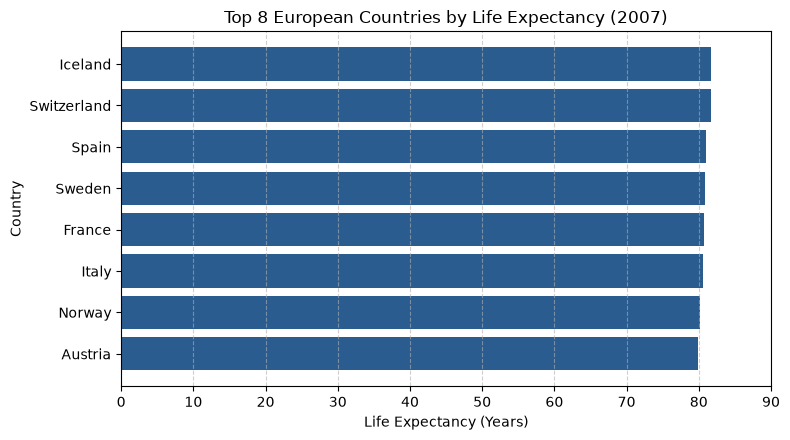

In [12]:
bad = gap_2007[gap_2007["continent"] == "Europe"].nlargest(8, "lifeExp")

plt.figure(figsize=(8, 4.5))
plt.barh(bad["country"], bad["lifeExp"], color="#2b5c8f")
plt.xlim(0, 90)
plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Country")
plt.title("Top 8 European Countries by Life Expectancy (2007)")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.gca().invert_yaxis()  # Rank highest to lowest top-down
plt.tight_layout()
plt.show()